# Step 5 – Centralized Baseline Models
**Project:** Paper Leak Sentiment Analysis Using Federated Learning

**Centralized** means all training comments are pooled on one machine. That gives no privacy, but it is the best case for accuracy.
These results are the **benchmark** the federated model (Step 7) is compared against in Step 8.

| # | Model | Features | Why it's included |
|---|---|---|---|
| 1 | Multinomial Naive Bayes | TF-IDF | classic, very fast text baseline |
| 2 | Logistic Regression | TF-IDF | strong linear baseline, gives probabilities |
| 3 | Linear SVM | TF-IDF | usually the strongest linear text classifier |
| 4 | SGD Logistic Regression | Hashing | **the exact model the federated clients will train** (FL reference) |

**Procedure:** each model's main setting is tuned on the **validation** set; the **test** set is used once at the end.

In [1]:
import sys, json, re
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import train_centralized
train_centralized.main()          # trains, tunes and evaluates all 4 models (about 20 seconds)

Naive Bayes                                test acc 0.9216  macro-F1 0.9213  (alpha=0.1, 0.1s)


Logistic Regression                        test acc 0.9231  macro-F1 0.9228  (C=0.5, 2.0s)


Linear SVM                                 test acc 0.9242  macro-F1 0.9239  (C=0.1, 1.1s)


SGD Logistic Regression (FL reference)     test acc 0.9223  macro-F1 0.9220  (alpha=1e-05, 0.5s)

Best: Linear SVM  acc 0.9242  macro-F1 0.9239


In [2]:
from matplotlib import font_manager
FONT = "Segoe UI" if any(f.name == "Segoe UI" for f in font_manager.fontManager.ttflist) else "DejaVu Sans"
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SENT = {"negative": "#e34948", "neutral": "#898781", "positive": "#2a78d6"}; ORDER = list(SENT)
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"font.family": FONT, "font.size": 10, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
    "savefig.dpi": 200, "savefig.bbox": "tight"})
FIG = ROOT / "results/figures"; TAB = ROOT / "results/tables"
def title(ax, main, sub=None):
    ax.set_title(main, loc="left", fontsize=13, fontweight="bold", color=INK, pad=24 if sub else 10)
    if sub: ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=9.5, color=INK2, va="bottom")
res = pd.read_csv(TAB / "centralized_results.csv")
tun = pd.read_csv(TAB / "centralized_tuning.csv")
pred = pd.read_csv(TAB / "centralized_test_predictions.csv")
summary = json.loads((ROOT / "reports/centralized_summary.json").read_text())

## 1. Results on the test set (10,000 comments never seen during training or tuning)

In [3]:
show = res[["model", "features", "accuracy", "precision", "recall", "f1", "f1_negative", "f1_neutral", "f1_positive", "best_param", "train_seconds"]].copy()
show.columns = ["Model", "Features", "Accuracy", "Precision", "Recall", "Macro-F1", "F1 neg", "F1 neu", "F1 pos", "Tuned setting", "Train time (s)"]
show.style.format({c: "{:.2%}" for c in ["Accuracy", "Precision", "Recall", "Macro-F1", "F1 neg", "F1 neu", "F1 pos"]}).hide(axis="index")

Model,Features,Accuracy,Precision,Recall,Macro-F1,F1 neg,F1 neu,F1 pos,Tuned setting,Train time (s)
Linear SVM,TF-IDF,92.42%,92.53%,92.42%,92.39%,92.68%,90.67%,93.82%,C=0.1,1.070000
Logistic Regression,TF-IDF,92.31%,92.41%,92.31%,92.28%,92.51%,90.54%,93.79%,C=0.5,2.050000
SGD Logistic Regression (FL reference),Hashing,92.23%,92.31%,92.23%,92.20%,92.38%,90.41%,93.82%,alpha=1e-05,0.550000
Naive Bayes,TF-IDF,92.16%,92.26%,92.16%,92.13%,92.57%,90.39%,93.43%,alpha=0.1,0.140000


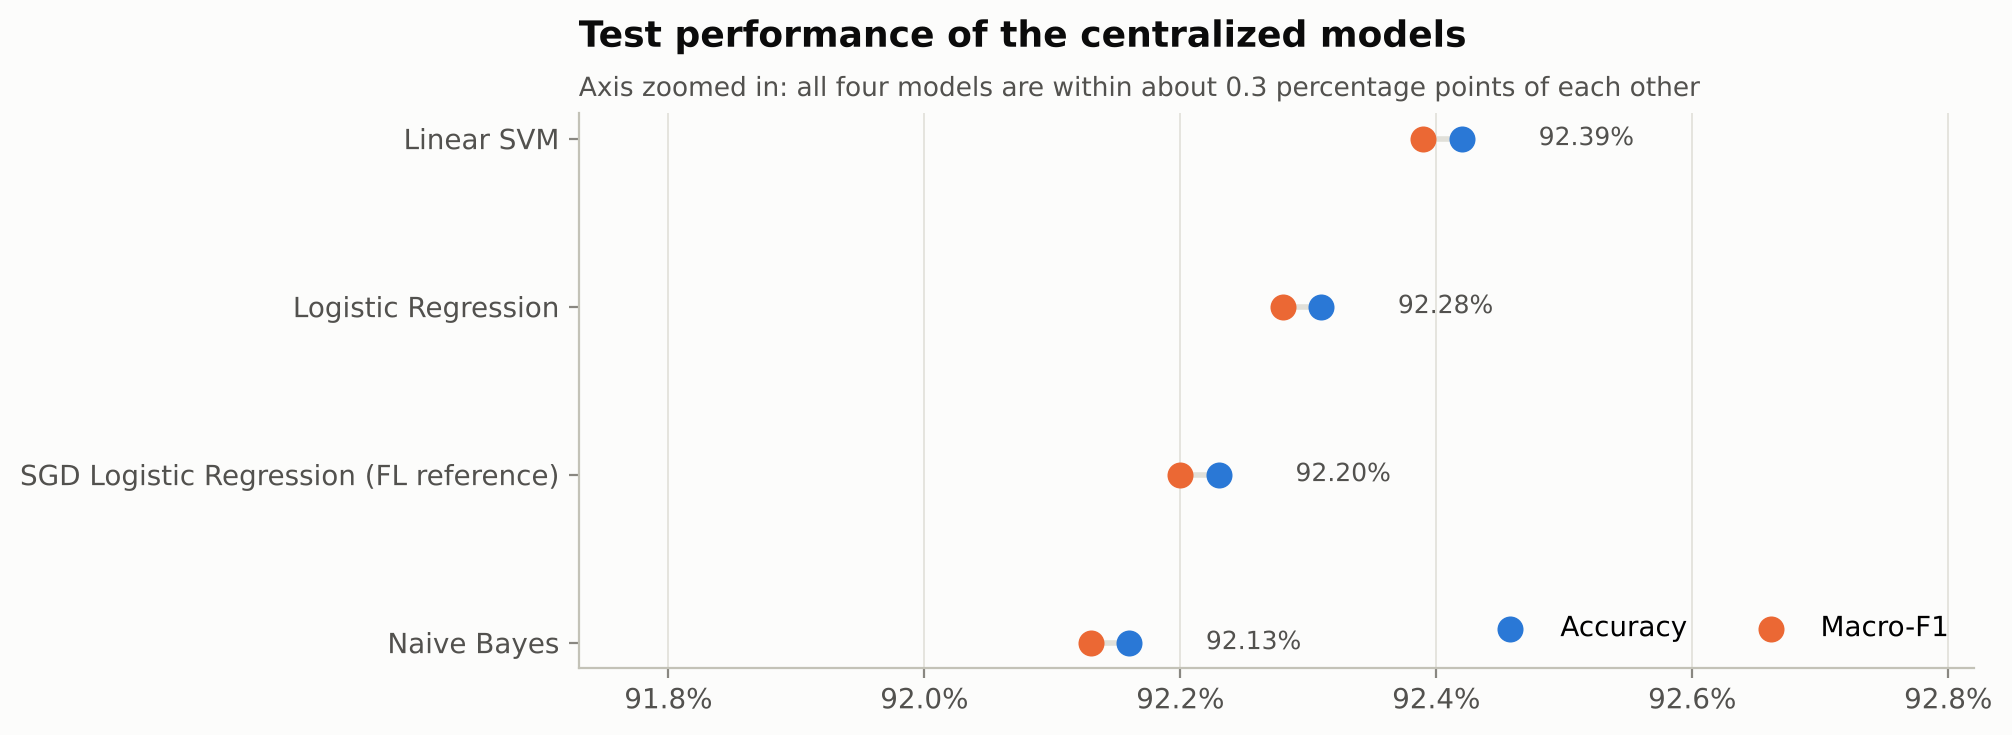

In [4]:
r = res.sort_values("f1")
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, row in enumerate(r.itertuples()):
    ax.plot([row.accuracy, row.f1], [i, i], color=GRID, lw=2, zorder=1)
    ax.scatter(row.accuracy, i, s=70, color=CAT[0], zorder=2, label="Accuracy" if i == 0 else None)
    ax.scatter(row.f1, i, s=70, color=CAT[1], zorder=2, label="Macro-F1" if i == 0 else None)
    ax.text(max(row.accuracy, row.f1) + 0.0006, i, f"{row.f1:.2%}", va="center", fontsize=9, color=INK2)
ax.set_yticks(range(len(r)), r.model); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.1%}")
lo = r[["accuracy", "f1"]].min().min(); ax.set_xlim(lo - 0.004, r[["accuracy", "f1"]].max().max() + 0.004)
ax.legend(loc="lower right", ncol=2)
title(ax, "Test performance of the centralized models", "Axis zoomed in: all four models are within about 0.3 percentage points of each other")
fig.savefig(FIG / "D1_centralized_model_comparison.png"); plt.show()

**Reading the results**
- All four models reach roughly **92% accuracy and macro-F1**, a realistic level for 3-class sentiment analysis.
- **Linear SVM is the best centralized model**, but the gap between the models is small. The features (TF-IDF and bigrams) matter more than the choice of classifier.
- The **SGD Logistic Regression on hashing features** scores almost the same as TF-IDF Logistic Regression. Switching to privacy-friendly hashing features for federated learning therefore costs almost nothing in accuracy.

## 2. Hyper-parameter tuning (validation set)

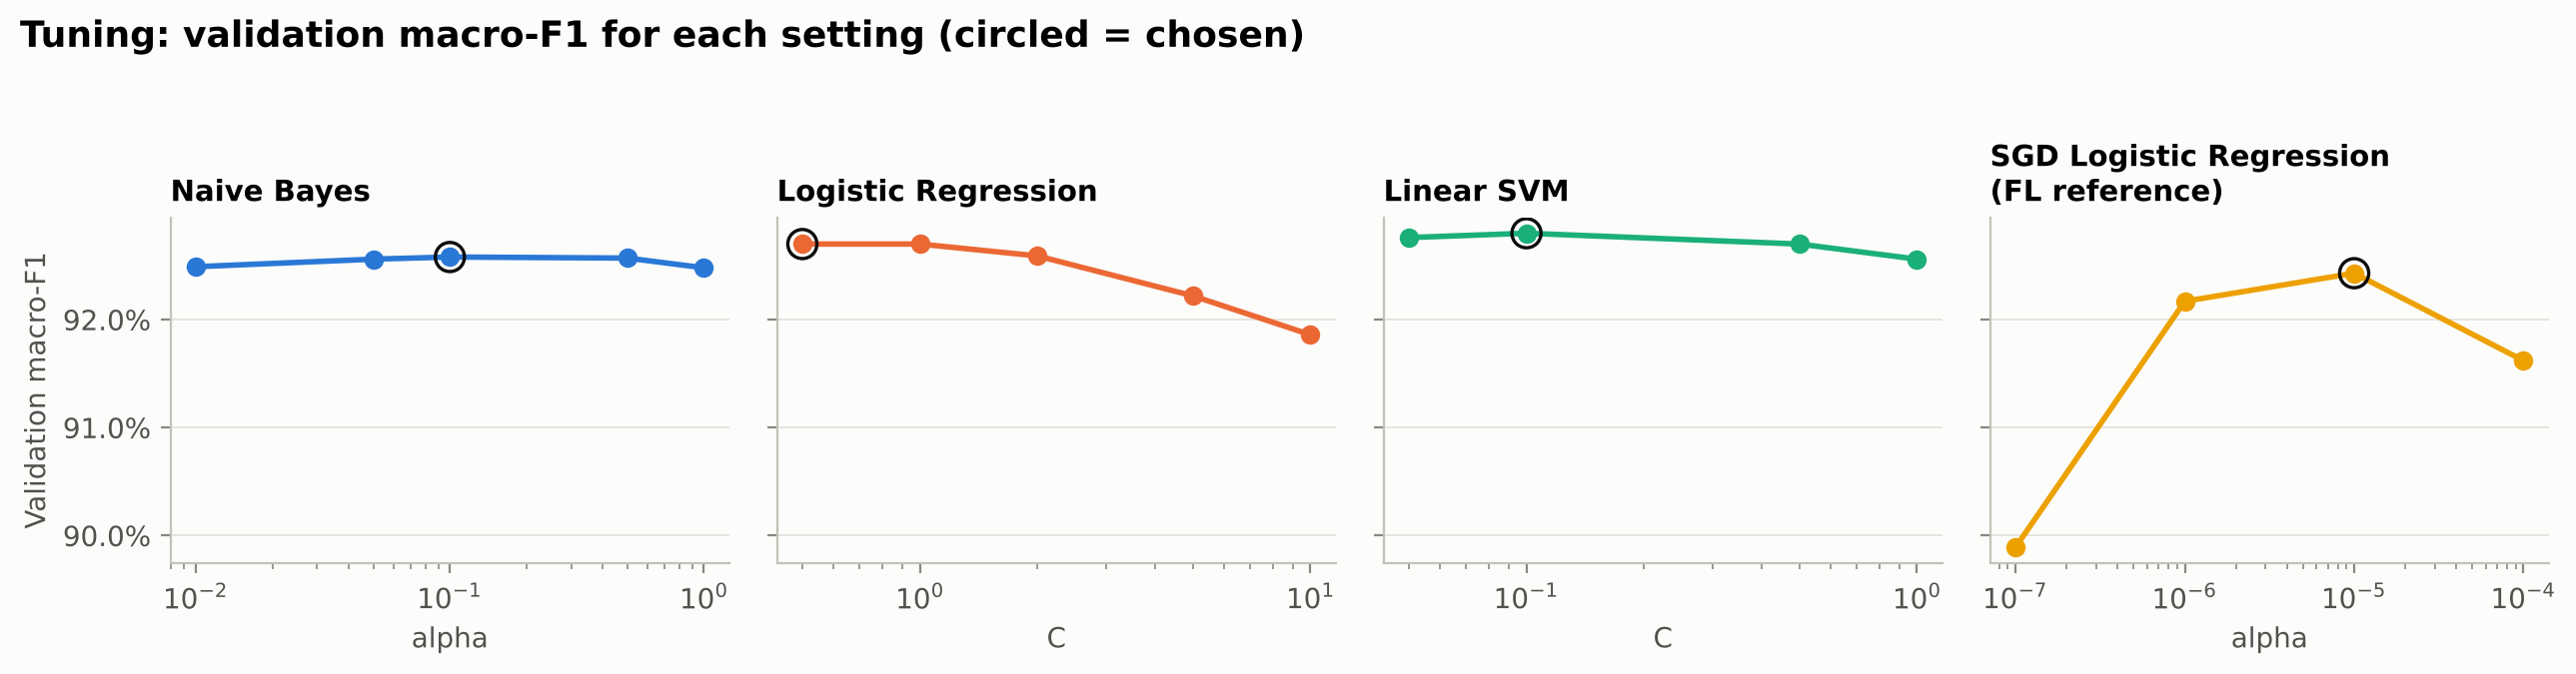

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, (name, g), col in zip(axes, tun.groupby("model", sort=False), CAT):
    ax.plot(g.value, g.val_macro_f1, color=col, lw=2, marker="o", ms=6)
    best = g.loc[g.val_macro_f1.idxmax()]
    ax.scatter(best.value, best.val_macro_f1, s=110, facecolor="none", edgecolor=INK, lw=1.2, zorder=3)
    ax.set_xscale("log"); ax.set_xlabel(g.param.iloc[0]); ax.grid(axis="x", visible=False)
    ax.set_title(name.replace(" (FL reference)", "\n(FL reference)"), loc="left", fontsize=10.5, fontweight="bold")
axes[0].set_ylabel("Validation macro-F1"); axes[0].yaxis.set_major_formatter(lambda x, _: f"{x:.1%}")
fig.suptitle("Tuning: validation macro-F1 for each setting (circled = chosen)", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout(); fig.savefig(FIG / "D2_tuning_curves.png"); plt.show()

## 3. Confusion matrix of the best model

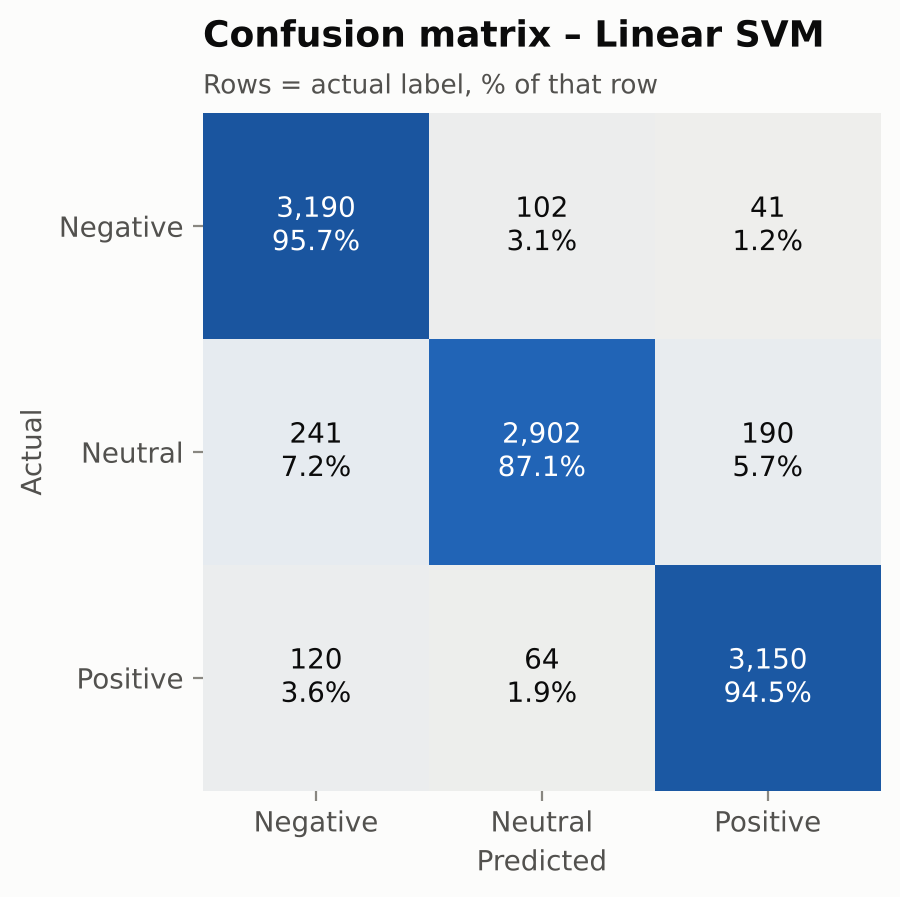

In [6]:
best = summary["best_model"]
col = {"Naive Bayes": "pred_naive_bayes", "Logistic Regression": "pred_logreg", "Linear SVM": "pred_linear_svm",
       "SGD Logistic Regression (FL reference)": "pred_sgd_hashing"}[best]
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(pred.label, pred[col], labels=ORDER)
cmn = cm / cm.sum(axis=1, keepdims=True)
from matplotlib.colors import LinearSegmentedColormap
blues = LinearSegmentedColormap.from_list("b", ["#f0efec", "#cde2fb", "#6da7ec", "#2a78d6", "#184f95"])
fig, ax = plt.subplots(figsize=(5.4, 4.4))
ax.imshow(cmn, cmap=blues, vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]:,}\n{cmn[i, j]:.1%}", ha="center", va="center", fontsize=10,
                color="#ffffff" if cmn[i, j] > 0.5 else INK)
ax.set_xticks(range(3), [c.capitalize() for c in ORDER]); ax.set_yticks(range(3), [c.capitalize() for c in ORDER])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
title(ax, f"Confusion matrix – {best}", "Rows = actual label, % of that row")
fig.savefig(FIG / "D3_confusion_matrix_best.png"); plt.show()

Most mistakes are between **neutral and one of the opinion classes**. Direct negative↔positive mix-ups are less common; many of them are sarcastic comments, for example *"Great job, another leak 👏"*.

## 4. Where does the best model struggle?

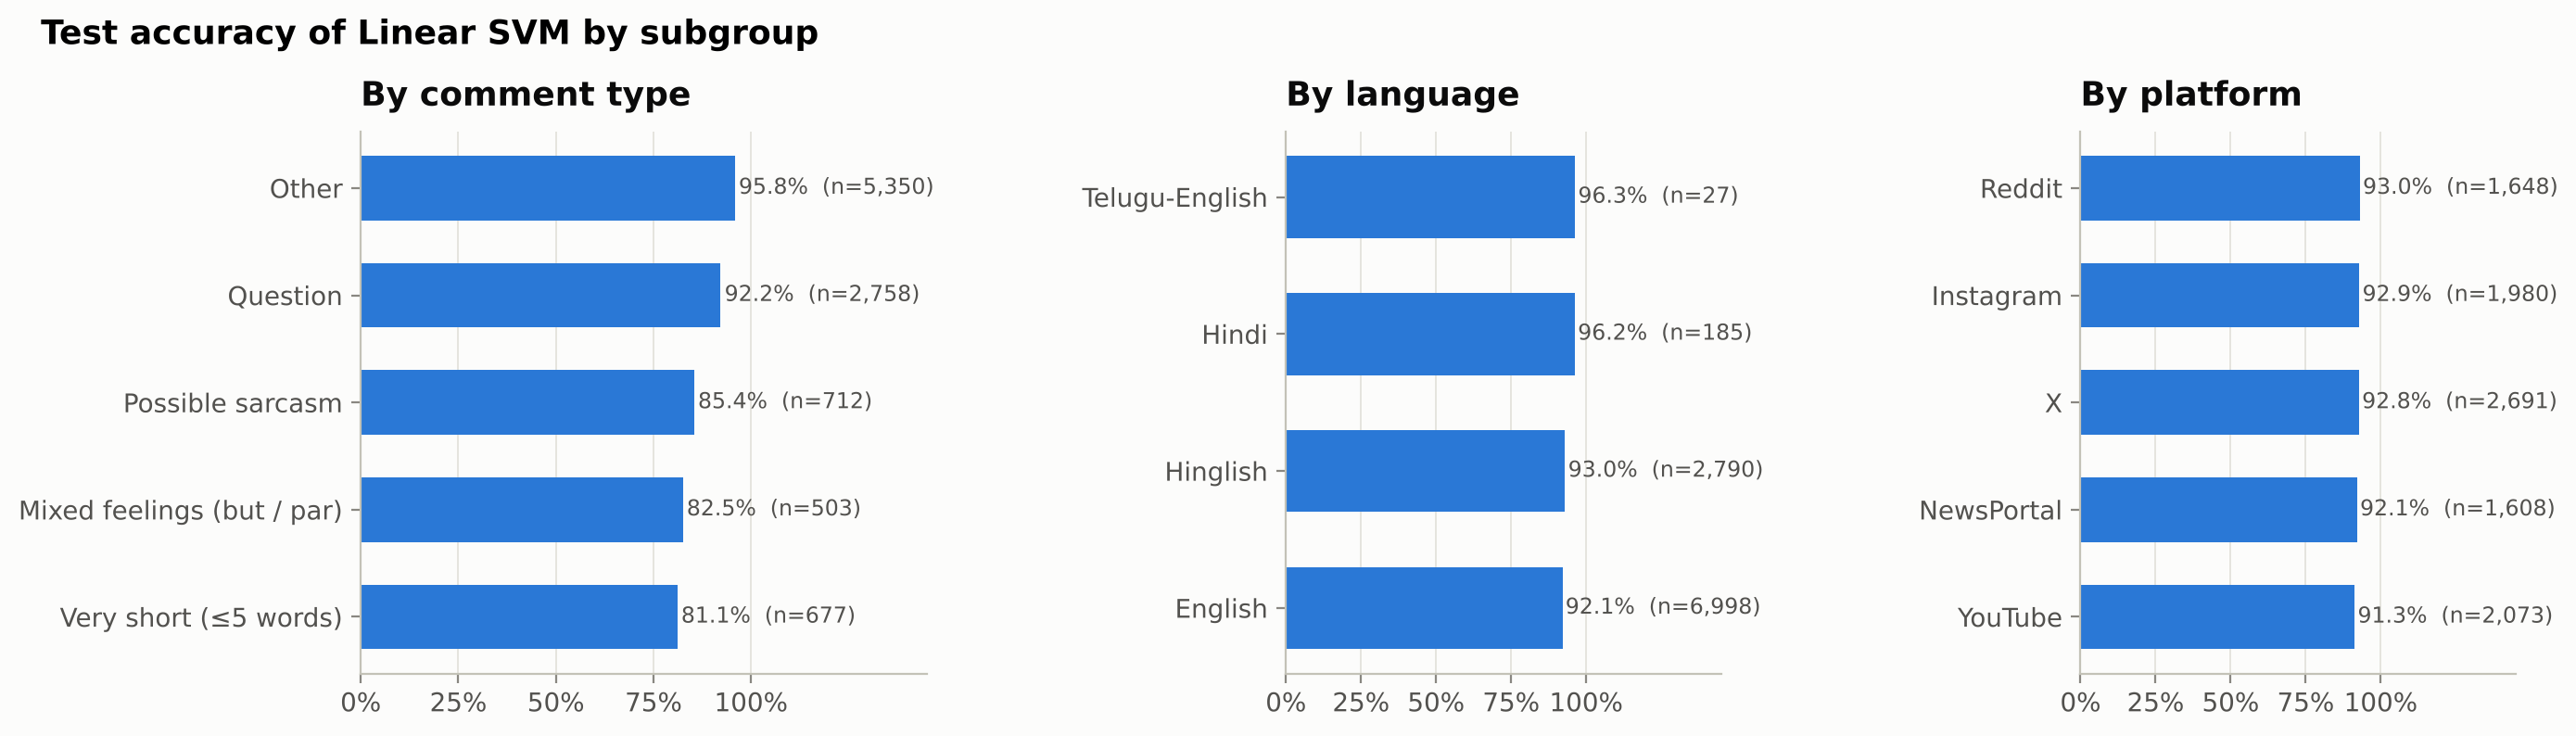

In [7]:
pred["correct"] = pred.label == pred[col]
def ctype(t):
    t = str(t)
    if len(t.split()) <= 5: return "Very short (≤5 words)"
    if re.search(r"👏|🙂|/s\b|\b(great job|fantastic|superb|wow|congrats|thank you|thanks|wah)\b", t, re.I): return "Possible sarcasm"
    if re.search(r"\b(but|par|though)\b", t, re.I): return "Mixed feelings (but / par)"
    if "?" in t: return "Question"
    return "Other"
pred["type"] = pred.text.map(ctype)
by_type = pred.groupby("type").agg(comments=("correct", "size"), accuracy=("correct", "mean")).sort_values("accuracy")
by_lang = pred.assign(language=pred.language.map({"en": "English", "hinglish": "Hinglish", "hi": "Hindi", "te-en": "Telugu-English"})) \
              .groupby("language").agg(comments=("correct", "size"), accuracy=("correct", "mean")).sort_values("accuracy")
by_plat = pred.groupby("platform").agg(comments=("correct", "size"), accuracy=("correct", "mean")).sort_values("accuracy")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.3, 1, 1], "wspace": 0.75})
for ax, (tab, name) in zip(axes, [(by_type, "By comment type"), (by_lang, "By language"), (by_plat, "By platform")]):
    ax.barh(tab.index, tab.accuracy, color=CAT[0], height=0.6)
    for i, (a, n) in enumerate(zip(tab.accuracy, tab.comments)):
        ax.text(a + 0.01, i, f"{a:.1%}  (n={n:,})", va="center", fontsize=8.5, color=INK2)
    ax.set_xlim(0, 1.45); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.set_xticks([0, .25, .5, .75, 1])
    ax.grid(axis="y", visible=False); title(ax, name)
fig.suptitle(f"Test accuracy of {best} by subgroup", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.04)
fig.savefig(FIG / "D4_accuracy_by_subgroup.png"); plt.show()

- **Very short, sarcastic and mixed-feeling comments are the hardest.** Even human annotators often disagree on these, and the dataset reflects that disagreement.
- Accuracy is similar across languages and platforms, because this centralized model saw **all** platforms during training. In Step 8 we will see what happens when a model trains on only one platform.

In [8]:
pd.set_option("display.max_colwidth", 110)
wrong = pred[~pred.correct].sample(10, random_state=7)[["platform", "text", "label", col]]
wrong.columns = ["platform", "comment", "actual", "predicted"]
wrong

,platform,comment,actual,predicted
8565,Instagram,"great. this setback will make us stronger. keep studying, the result will come. 🙏",neutral,positive
8352,Instagram,kya maltab mehnat ka? #justiceforaspirants #ukpscpatwarilekhpalexam,negative,neutral
1986,X,"Many are upset, some are so relieved. Will the result be declared? #News #ExamUpdate",negative,neutral
9517,NewsPortal,FIRs filed in the Vyapam food inspector exam case 👍,neutral,positive
9157,Instagram,"i mean, solid that they responded, but hardworking candidates are the only ones who suffer every time. #pa...",positive,negative
4280,NewsPortal,"Bro nearly 9 lakh students affected. According to reports, NTA says the paper was safe.",positive,neutral
4103,YouTube,students ne Patwari exam 2021 pe aawaz uthai 👏,neutral,positive
9432,YouTube,"bura to laga, par hasula rakho, sach ki jeet hogi",negative,positive
8041,NewsPortal,My daughter studied day and night for this. Now she just sits quietly in her room. Who is answerable for t...,neutral,negative
5599,YouTube,resppect 👏,neutral,positive


## 5. Summary – the benchmark for federated learning

In [9]:
fl_ref = res.set_index("model").loc["SGD Logistic Regression (FL reference)"]
bestr = res.iloc[0]
pd.DataFrame({"": ["Best centralized model", "Accuracy", "Macro-F1",
                   "FL reference (SGD + hashing) accuracy", "FL reference macro-F1", "Trained on"],
              "value": [bestr.model, f"{bestr.accuracy:.2%}", f"{bestr.f1:.2%}", f"{fl_ref.accuracy:.2%}", f"{fl_ref.f1:.2%}",
                        "80,002 pooled comments from all 5 platforms (no privacy)"]}).style.hide(axis="index")

,value
Best centralized model,Linear SVM
Accuracy,92.42%
Macro-F1,92.39%
FL reference (SGD + hashing) accuracy,92.23%
FL reference macro-F1,92.20%
Trained on,"80,002 pooled comments from all 5 platforms (no privacy)"


**What these numbers mean for the project**
- **About 92% is the upper bound.** It is what we get when all data can be collected in one place.
- Step 7 trains the **same SGD model** in a federated way: each platform keeps its own comments and only sends model weights to the server.
- **Objective 2 is met** if the federated model gets **close to this benchmark** while sharing no raw comments.

**Next:** Step 6 – split the training data into the 5 platform clients.